# 05 · Paired H&E patch – spot RNA dataset (data preparation only)

**What this notebook does.** For each tissue section listed in `SECTIONS` (cell 5.1; currently **B1** and **A24**),
it selects about 30–50 QC-passing spots and, for each spot, saves:
1. an **H&E image patch** cut from the H&E image, centred on the spot's position;
2. the **RNA profile of the exact same spot** (same `spot_uid` = capture area + barcode).

It then checks the pairing programmatically and shows a montage for visual checking. Every step runs once per
section; each section gets its own output folder and its own figures, so the sections are never mixed.

**What this dataset is, and is not.**
* Each RNA profile is **spot-level**: the summed transcripts of all cells under one 55 µm spot (the paper states 5–10
  cells per spot). It is **not** a single-cell measurement.
* The H&E patch comes from the images distributed in GEO. The hires image has a pixel size of several µm (notebook 03,
  3.2), so patches show tissue architecture and colour, **not** individual cells.
* The two sections come from two different patients and have different pixel sizes, so the same patch size in µm
  corresponds to a different number of pixels in each section (recorded in the tables).
* This is pairing preparation only. Nothing here measures biological similarity or retrieval accuracy.

| | |
|---|---|
| **Inputs** | processed `.h5ad` (with QC), raw images, `manifests/qc_summary.csv`, `manifests/capture_areas.csv`, `manifests/tissue_sections.csv` |
| **Outputs** | per section: `manifests/paired_spots/<GSM>_<section>/` with `paired_spots.csv`, `patches/*.png`, `rna_counts.npz`, `rna_lognorm_cp10k.npz`, `rna_genes.csv`, `rna_rows.csv`, `pairing_checks.csv`; `figures/05_paired/<GSM>_<section>_*.png`. Across sections: `manifests/paired_spots/paired_sections_summary.csv` |

In [1]:
# --- Setup: make src/ importable, load helpers, define all paths -------------
import sys
from pathlib import Path
REPO = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(REPO / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import spacemel_io as sio        # all data processing
import spacemel_plots as splot   # all drawing

P = sio.get_paths()
sio.ensure_output_dirs(P)
FIG = P["figures"] / "05_paired"
FIG.mkdir(parents=True, exist_ok=True)
MAN = P["manifests"]
pd.set_option("display.max_columns", 60, "display.width", 220, "display.max_colwidth", 80)
print("repo      :", P["repo"])
print("raw data  :", P["raw"])
print("figures ->:", FIG)
print("manifests:", MAN)

repo      : C:\Users\Kerekes Kinga\Downloads\multimodal-retrieval
raw data  : C:\Users\Kerekes Kinga\Downloads\multimodal-retrieval\data\GSE298774\raw
figures ->: C:\Users\Kerekes Kinga\Downloads\multimodal-retrieval\figures\05_paired
manifests: C:\Users\Kerekes Kinga\Downloads\multimodal-retrieval\manifests


## 5.1 · Parameters (set these before running the rest)

* `SECTIONS`: the sections to use (file tokens, as listed in 5.2). Currently `["B1", "A24"]`:
  * **A24** is the section recommended in the task instructions; in 5.2 it has the highest sequencing depth.
  * **B1** was the first section run; in 5.2 it has one of the highest QC pass rates.
  * Check both reasons against the 5.2 table of your own run.
* `IMAGE_SOURCE`: `"hires"` (default). `aligned_fiducials.jpg` is not used (notebook 03, 3.3).
* `CONTEXT_PATCH_UM = 255`: side of the context patch. Chosen so the patch fully contains the spot and its six
  immediate neighbours: 100 µm centre distance + 27.5 µm spot radius = 127.5 µm on each side → 255 µm. This is a
  design choice, to be varied later (patch-size ablation). The same value in µm is used for every section.
* `SPOT_PATCH_UM = 55`: a second, spot-only crop (one spot diameter).
* `N_SPOTS = 40`, `SEED = 0`: number of pairs **per section** and random seed (selection is reproducible).
* `MIN_DIST_UM = CONTEXT_PATCH_UM`: within a section, selected spots are at least this far apart, so no two context
  patches share pixels.
* `N_MONTAGE = 8`: pairs shown in the montage of each section (at least 5).

In [2]:
SECTIONS = ["B1", "A24"]   # <- sections to process, chosen from 5.2
IMAGE_SOURCE = "hires"
CONTEXT_PATCH_UM = 255.0
SPOT_PATCH_UM = 55.0
N_SPOTS = 40               # per section
SEED = 0
MIN_DIST_UM = CONTEXT_PATCH_UM
N_MONTAGE = 8              # pairs shown in each section's montage (at least 5)

## 5.2 · Candidate sections

Information to choose from (not an automatic choice): QC-passing spots, depth, whether the paper analysed the
section, and the H&E pixel size of its capture area. The rows of the sections in `SECTIONS` are shown again below
the full table.

In [3]:
qc_summary = pd.read_csv(MAN / "qc_summary.csv")
ca = pd.read_csv(MAN / "capture_areas.csv")[["gsm", "um_per_hires_px", "spot55um_in_hires_px", "um_per_fiducials_px"]]
cand = qc_summary.merge(ca, on="gsm")[["section_id", "gsm", "patient_id", "in_paper_S1C", "n_spots", "n_pass",
                                       "median_counts", "median_genes", "um_per_hires_px", "spot55um_in_hires_px"]]
display(cand.sort_values("n_pass", ascending=False))
cand[cand.section_id.isin(SECTIONS)]

,section_id,gsm,patient_id,in_paper_S1C,n_spots,n_pass,median_counts,median_genes,um_per_hires_px,spot55um_in_hires_px
3,A24,GSM9022967,A24,True,6165,6059,11291.0,3400.0,11.27,4.9
7,B4,GSM9022970,B4,True,6415,5419,3374.0,1199.0,9.07,6.1
5,A22,GSM9022967,A22,True,4326,4081,4010.0,1546.0,11.27,4.9
1,B1,GSM9022969,B1,True,3952,3931,19684.5,5075.0,8.73,6.3
9,A16,GSM9022966,A16,True,5195,2768,1246.0,554.0,11.78,4.7
8,A23,GSM9022966,A23,True,2782,2143,2811.5,1099.0,11.78,4.7
4,A21,GSM9022965,A21,True,2260,1934,5914.5,2129.0,7.80,7.1
2,B38ex,GSM9022969,B38,False,1861,1855,11309.0,3469.0,8.73,6.3
12,A34,GSM9022968,A34,True,4151,1631,507.0,300.0,8.90,6.2
11,B13,GSM9022971,B13,True,3614,1536,752.0,402.0,8.80,6.3


,section_id,gsm,patient_id,in_paper_S1C,n_spots,n_pass,median_counts,median_genes,um_per_hires_px,spot55um_in_hires_px
1,B1,GSM9022969,B1,True,3952,3931,19684.5,5075.0,8.73,6.3
3,A24,GSM9022967,A24,True,6165,6059,11291.0,3400.0,11.27,4.9


In [4]:
# One entry per section: capture area and output folder. All later cells store their results in R[section].
assert len(SECTIONS) > 0, "Set SECTIONS in 5.1 (section_ids from the table above), then re-run from 5.1."
missing = [s for s in SECTIONS if s not in set(cand.section_id)]
assert not missing, f"Not in the candidate table: {missing}"
R = {}
for s in SECTIONS:
    gsm = cand.set_index("section_id").loc[s, "gsm"]
    out = MAN / "paired_spots" / f"{gsm}_{s}"
    (out / "patches").mkdir(parents=True, exist_ok=True)
    R[s] = {"gsm": gsm, "out": out}
    print("section:", s, "| capture area:", gsm, "| output:", out)

section: B1 | capture area: GSM9022969 | output: C:\Users\Kerekes Kinga\Downloads\multimodal-retrieval\manifests\paired_spots\GSM9022969_B1
section: A24 | capture area: GSM9022967 | output: C:\Users\Kerekes Kinga\Downloads\multimodal-retrieval\manifests\paired_spots\GSM9022967_A24


## 5.3 · Load each section, its image and the spot positions in image pixels

Image pixel position of a spot = full-resolution pixel position × the image's scale factor (notebook 03).
Patch sizes in pixels are computed per section from that section's µm per pixel (odd number, so the spot is the
centre pixel).

In [5]:
for s, r in R.items():
    a_all = sio.read_processed(P, r["gsm"], s)
    img, x_all, y_all, um_img = sio.section_image(P, a_all, IMAGE_SOURCE)
    qc_mask = a_all.obs.qc_pass.to_numpy()
    r.update(a_all=a_all, img=img, um_img=um_img,
             a=a_all[qc_mask].copy(), x=x_all[qc_mask], y=y_all[qc_mask],
             ctx_px=sio.odd_side_px(CONTEXT_PATCH_UM, um_img),
             spot_px=sio.odd_side_px(SPOT_PATCH_UM, um_img))

pd.DataFrame({s: {"image": IMAGE_SOURCE,
                  "image size (px)": f'{r["img"].shape[1]} x {r["img"].shape[0]}',
                  "µm per image px": round(r["um_img"], 2),
                  "context patch (px)": r["ctx_px"], "context patch (µm)": round(r["ctx_px"] * r["um_img"]),
                  "spot patch (px)": r["spot_px"], "spot patch (µm)": round(r["spot_px"] * r["um_img"]),
                  "QC-passing spots": r["a"].n_obs, "spots in tissue": r["a_all"].n_obs}
              for s, r in R.items()})

,B1,A24
image,hires,hires
image size (px),2000 x 1934,2000 x 1834
µm per image px,8.73,11.27
context patch (px),29,23
context patch (µm),253,259
spot patch (px),7,5
spot patch (µm),61,56
QC-passing spots,3931,6059
spots in tissue,3952,6165


## 5.4 · Select spots (per section)

Candidates = QC-passing spots whose whole context patch lies inside the image (no padding is invented).
From these, `N_SPOTS` are drawn at random (fixed seed), keeping only spots at least `MIN_DIST_UM` apart.
Selection is done separately in each section.

In [6]:
for s, r in R.items():
    img, x, y, a = r["img"], r["x"], r["y"], r["a"]
    inside = np.array([sio.crop_centered(img, xi, yi, r["ctx_px"]) is not None for xi, yi in zip(x, y)])
    cand_idx = np.where(inside)[0]
    pick = cand_idx[sio.select_spread_spots(a.obsm["spatial_um"][cand_idx], N_SPOTS, MIN_DIST_UM, SEED)]
    r.update(n_inside=int(inside.sum()), pick=pick, sel=a[pick].copy(), sel_x=x[pick], sel_y=y[pick])
    print(f"{s}: inside image {inside.sum()} | selected {len(pick)}")
    if len(pick) < N_SPOTS:
        print(f"  {s}: fewer spots than requested satisfy the distance rule; this is recorded, not padded.")

B1: inside image 3931 | selected 40
A24: inside image 6059 | selected 40


## 5.5 · Cut and save the patches

Patches are saved as PNG at the image's **native** pixel size (no resampling), so they are exactly the image pixels.
File names start with the pair ID, which starts with the section (e.g. `A24_000`).

In [7]:
from PIL import Image
for s, r in R.items():
    recs = []
    for i, (uid, xi, yi) in enumerate(zip(r["sel"].obs.spot_uid, r["sel_x"], r["sel_y"])):
        pid = f"{s}_{i:03d}"
        ctx = sio.crop_centered(r["img"], xi, yi, r["ctx_px"])
        spt = sio.crop_centered(r["img"], xi, yi, r["spot_px"])
        f_ctx = r["out"] / "patches" / f"{pid}_context.png"
        f_spt = r["out"] / "patches" / f"{pid}_spot.png"
        Image.fromarray(ctx).save(f_ctx)
        Image.fromarray(spt).save(f_spt)
        recs.append({"pair_id": pid, "spot_uid": uid, "img_x": xi, "img_y": yi,
                     "patch_context_file": f_ctx.relative_to(MAN).as_posix(),
                     "patch_spot_file": f_spt.relative_to(MAN).as_posix()})
    r["patches"] = pd.DataFrame(recs)
    print(f"{s}: {len(recs)} pairs written to", r["out"] / "patches")

B1: 40 pairs written to C:\Users\Kerekes Kinga\Downloads\multimodal-retrieval\manifests\paired_spots\GSM9022969_B1\patches
A24: 40 pairs written to C:\Users\Kerekes Kinga\Downloads\multimodal-retrieval\manifests\paired_spots\GSM9022967_A24\patches


## 5.6 · Save the RNA profiles of the same spots

Row *i* of each matrix = the spot of `pair_id` *i* (listed in `rna_rows.csv`). Written separately for each section:
* `rna_counts.npz`: raw UMI counts for all genes of the panel (sparse matrix, spots × genes);
* `rna_lognorm_cp10k.npz`: log(1 + counts / spot total × 10,000), computed per spot from the same counts;
* `rna_genes.csv`: gene symbol and Ensembl ID for each column.

These are the RNA feature representations; no gene selection or dimensionality reduction is applied yet. The number
of genes can differ between sections (18,085 or 37,082 depending on the matrix, notebook 01, 1.5); the columns of two
sections must be matched by `gene_id` before they are compared.

In [8]:
import scipy.sparse as sps
for s, r in R.items():
    sel, out = r["sel"], r["out"]
    sel_norm = sio.lognormalised_copy(sel)
    sps.save_npz(out / "rna_counts.npz", sps.csr_matrix(sel.layers["counts"]))
    sps.save_npz(out / "rna_lognorm_cp10k.npz", sps.csr_matrix(sel_norm.X))
    sel.var[["gene_id", "gene_symbol"]].assign(column=range(sel.n_vars)).to_csv(out / "rna_genes.csv", index=False)
    pd.DataFrame({"row": range(sel.n_obs), "pair_id": r["patches"].pair_id, "spot_uid": sel.obs.spot_uid.values}
                 ).to_csv(out / "rna_rows.csv", index=False)
    print(f"{s}: genes per profile: {sel.n_vars}")

B1: genes per profile: 37082
A24: genes per profile: 37082


## 5.7 · The paired-spot table

One table per section, one row per pair, with patient, capture area, barcode, all coordinates, patch scale, QC values
and file locations. The first rows of each section are shown.

In [9]:
ID_COLS = ["spot_uid", "patient_id", "gsm", "section_id", "barcode"]
for s, r in R.items():
    o, um_img, ctx_px, spot_px = r["sel"].obs, r["um_img"], r["ctx_px"], r["spot_px"]
    paired = r["patches"].assign(
        patient_id=o.patient_id.values, gsm=o.gsm.values, section_id=o.section_id.values, barcode=o.barcode.values,
        array_row=o.array_row.values, array_col=o.array_col.values,
        pxl_row_in_fullres=o.pxl_row_in_fullres.values, pxl_col_in_fullres=o.pxl_col_in_fullres.values,
        x_um=o.x_um.values, y_um=o.y_um.values,
        image_source=IMAGE_SOURCE, um_per_image_px=round(um_img, 3),
        patch_context_px=ctx_px, patch_context_um=round(ctx_px * um_img, 1),
        patch_spot_px=spot_px, patch_spot_um=round(spot_px * um_img, 1),
        total_counts=o.total_counts.values, n_genes=o.n_genes.values, pct_mt=o.pct_mt.values, qc_pass=o.qc_pass.values,
        rna_row=range(len(r["patches"])), rna_files="rna_counts.npz;rna_lognorm_cp10k.npz",
        rna_measurement="Visium spot, 55 um, mixture of cells (not single-cell)",
        region_label="not available",
    )
    paired[ID_COLS] = paired[ID_COLS].astype(str)
    paired.to_csv(r["out"] / "paired_spots.csv", index=False)
    r["paired"] = paired
pd.concat([r["paired"].head(3) for r in R.values()], ignore_index=True)

,pair_id,spot_uid,img_x,img_y,patch_context_file,patch_spot_file,patient_id,gsm,section_id,barcode,array_row,array_col,pxl_row_in_fullres,pxl_col_in_fullres,x_um,y_um,image_source,um_per_image_px,patch_context_px,patch_context_um,patch_spot_px,patch_spot_um,total_counts,n_genes,pct_mt,qc_pass,rna_row,rna_files,rna_measurement,region_label
0,B1_000,GSM9022969:TCTACTCCAAGGCAGA-1,1343.099260,814.255781,paired_spots/GSM9022969_B1/patches/B1_000_context.png,paired_spots/GSM9022969_B1/patches/B1_000_spot.png,B1,GSM9022969,B1,TCTACTCCAAGGCAGA-1,65,13,21956,36216,11719.836009,7105.166761,hires,8.726,29,253.1,7,61.1,6702.0,2046,2.103850,True,0,rna_counts.npz;rna_lognorm_cp10k.npz,"Visium spot, 55 um, mixture of cells (not single-cell)",not available
1,B1_001,GSM9022969:GCAGATTCACGCGGCT-1,1059.244562,1158.078214,paired_spots/GSM9022969_B1/patches/B1_001_context.png,paired_spots/GSM9022969_B1/patches/B1_001_spot.png,B1,GSM9022969,B1,GCAGATTCACGCGGCT-1,100,62,31227,28562,9242.930089,10105.348991,hires,8.726,29,253.1,7,61.1,85021.0,9711,3.260371,True,1,rna_counts.npz;rna_lognorm_cp10k.npz,"Visium spot, 55 um, mixture of cells (not single-cell)",not available
2,B1_002,GSM9022969:ATTCAGATTCTACATT-1,1196.981216,1119.842756,paired_spots/GSM9022969_B1/patches/B1_002_context.png,paired_spots/GSM9022969_B1/patches/B1_002_spot.png,B1,GSM9022969,B1,ATTCAGATTCTACATT-1,96,38,30196,32276,10444.815193,9771.707757,hires,8.726,29,253.1,7,61.1,4891.0,1799,4.089143,True,2,rna_counts.npz;rna_lognorm_cp10k.npz,"Visium spot, 55 um, mixture of cells (not single-cell)",not available
3,A24_000,GSM9022967:ATGTACTTACTGACGC-1,802.158648,466.335449,paired_spots/GSM9022967_A24/patches/A24_000_context.png,paired_spots/GSM9022967_A24/patches/A24_000_spot.png,A24,GSM9022967,A24,ATGTACTTACTGACGC-1,16,152,13610,23411,9038.389836,5254.473780,hires,11.268,23,259.2,5,56.3,23709.0,3970,1.273778,True,0,rna_counts.npz;rna_lognorm_cp10k.npz,"Visium spot, 55 um, mixture of cells (not single-cell)",not available
4,A24_001,GSM9022967:TAGACATTCCATACAT-1,873.633721,856.844274,paired_spots/GSM9022967_A24/patches/A24_001_context.png,paired_spots/GSM9022967_A24/patches/A24_001_spot.png,A24,GSM9022967,A24,TAGACATTCCATACAT-1,67,137,25007,25497,9843.741218,9654.564719,hires,11.268,23,259.2,5,56.3,150736.0,10819,8.607764,True,1,rna_counts.npz;rna_lognorm_cp10k.npz,"Visium spot, 55 um, mixture of cells (not single-cell)",not available
5,A24_002,GSM9022967:CGACTGAACACTGGTT-1,921.466512,1132.568107,paired_spots/GSM9022967_A24/patches/A24_002_context.png,paired_spots/GSM9022967_A24/patches/A24_002_spot.png,A24,GSM9022967,A24,CGACTGAACACTGGTT-1,103,127,33054,26893,10382.701203,12761.306123,hires,11.268,23,259.2,5,56.3,186316.0,11004,6.113270,True,2,rna_counts.npz;rna_lognorm_cp10k.npz,"Visium spot, 55 um, mixture of cells (not single-cell)",not available


## 5.8 · Programmatic pairing checks

Run separately for each section. Each check must be `True`:
1. RNA rows are in the same order and have the same `spot_uid` as the patch table;
2. every `spot_uid` matches its capture area and barcode;
3. every selected spot passed QC;
4. re-reading each saved patch gives exactly the pixels of the image around the spot's position;
5. no two selected spots are closer than `MIN_DIST_UM` (no shared patch pixels);
6. every RNA profile has non-zero counts.

Each section's results are saved in its own `pairing_checks.csv`; the table below shows one column per section.

In [10]:
all_checks = {}
for s, r in R.items():
    out, paired, sel = r["out"], r["paired"], r["sel"]
    rows_back = pd.read_csv(out / "rna_rows.csv")
    counts_back = sps.load_npz(out / "rna_counts.npz")
    xy = sel.obsm["spatial_um"]
    dmin = min(np.hypot(*(xy[i] - xy[j])) for i in range(len(xy)) for j in range(i)) if len(xy) > 1 else np.inf
    checks = {
        "1_rna_rows_match_patch_table": list(rows_back.spot_uid) == list(paired.spot_uid),
        "2_uid_equals_gsm_colon_barcode": bool((paired.spot_uid.astype(str)
                                                == paired.gsm.astype(str) + ":" + paired.barcode.astype(str)).all()),
        "3_all_qc_pass": bool(paired.qc_pass.all()),
        "4_saved_patches_equal_image_crops": all(
            np.array_equal(np.asarray(Image.open(MAN / p.patch_context_file)),
                           sio.crop_centered(r["img"], p.img_x, p.img_y, r["ctx_px"]))
            for p in paired.itertuples()),
        "5_min_distance_um_ok": bool(dmin >= MIN_DIST_UM),
        "6_all_profiles_nonzero": bool((np.asarray(counts_back.sum(axis=1)).ravel() > 0).all()),
    }
    pairing_checks = pd.Series(checks, name="passed").to_frame().assign(min_pair_distance_um=round(float(dmin), 1))
    pairing_checks.to_csv(out / "pairing_checks.csv")
    r.update(checks=checks, dmin=float(dmin))
    all_checks[s] = {**checks, "min_pair_distance_um": round(float(dmin), 1)}
pd.DataFrame(all_checks)

,B1,A24
1_rna_rows_match_patch_table,True,True
2_uid_equals_gsm_colon_barcode,True,True
3_all_qc_pass,True,True
4_saved_patches_equal_image_crops,True,True
5_min_distance_um_ok,True,True
6_all_profiles_nonzero,True,True
min_pair_distance_um,264.3,264.8


## 5.9 · Where the selected spots are

One figure per section: all QC-passing spots in grey, selected spots outlined in red (square-sized circle = context
patch) and numbered by pair index.

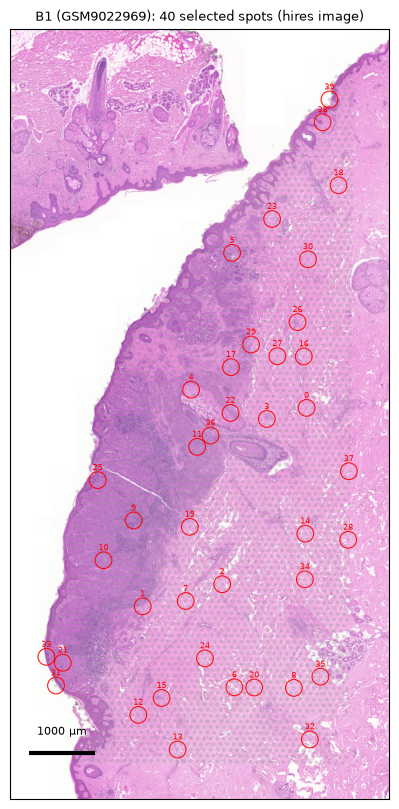

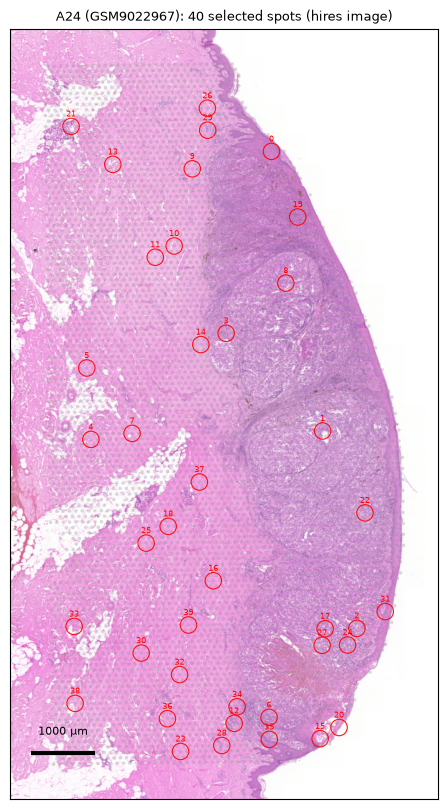

In [11]:
for s, r in R.items():
    img, x, y, um_img, ctx_px = r["img"], r["x"], r["y"], r["um_img"], r["ctx_px"]
    d_img = sio.SPOT_DIAMETER_UM / um_img
    fig, ax = plt.subplots(figsize=(10, 10))
    splot.section_map(ax, img, x, y, d_img, um_img, color="0.6", alpha=0.35,
                      title=f"{s} ({r['gsm']}): {len(r['paired'])} selected spots ({IMAGE_SOURCE} image)")
    splot.spot_circles(ax, r["sel_x"], r["sel_y"], ctx_px, color="red", edge_only=True, lw=0.8)
    for i, (xi, yi) in enumerate(zip(r["sel_x"], r["sel_y"])):
        ax.text(xi, yi - ctx_px * 0.6, str(i), color="red", fontsize=6, ha="center")
    splot.savefig(fig, FIG / f"{r['gsm']}_{s}_selected_spots.png")
    plt.show()

## 5.10 · Montage of pairs

One montage per section. For `N_MONTAGE` pairs: left, the context patch (native pixels, enlarged without smoothing)
in µm around the spot centre, with the selected spot (red, 55 µm) and neighbouring array spots (white) drawn at true
size; right, the ten genes with the most UMI counts in **the same spot**. Use it to check visually that the red circle
sits where the spot's tissue is and that neighbouring circles follow the spot grid. The two sections have different
pixel sizes, so their patches look differently coarse.

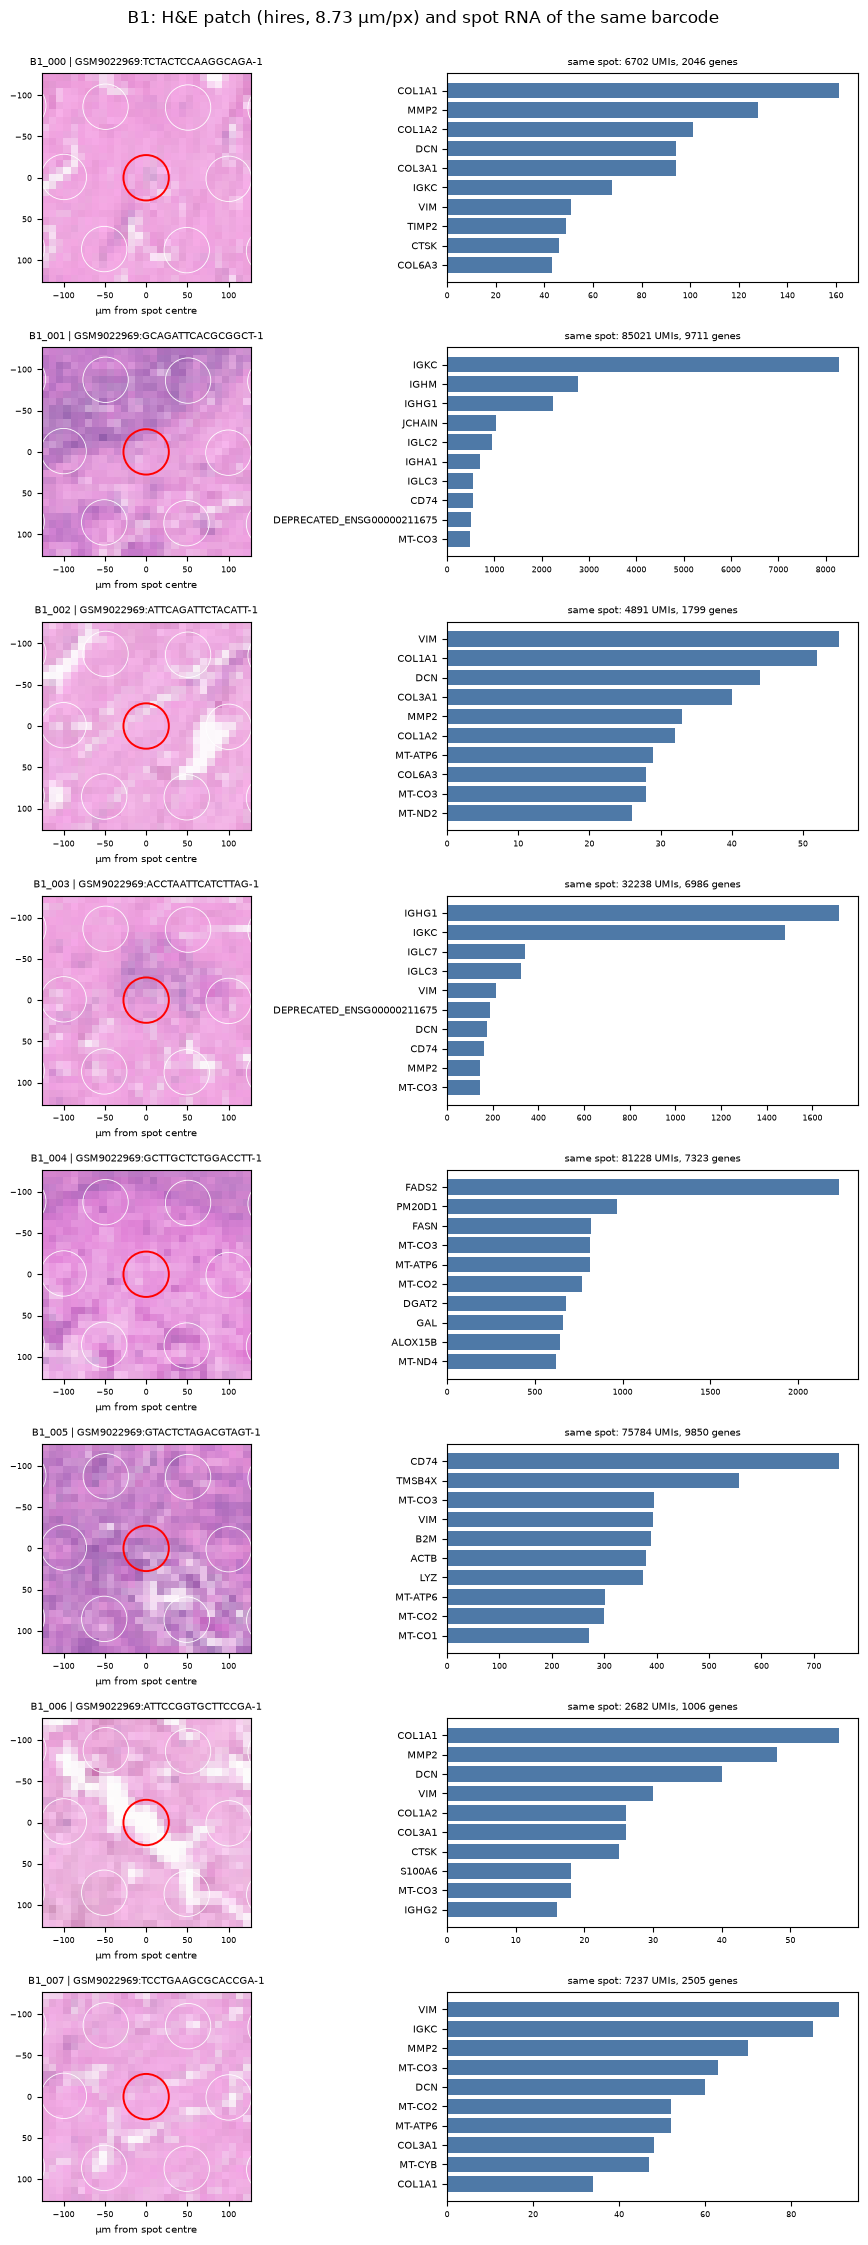

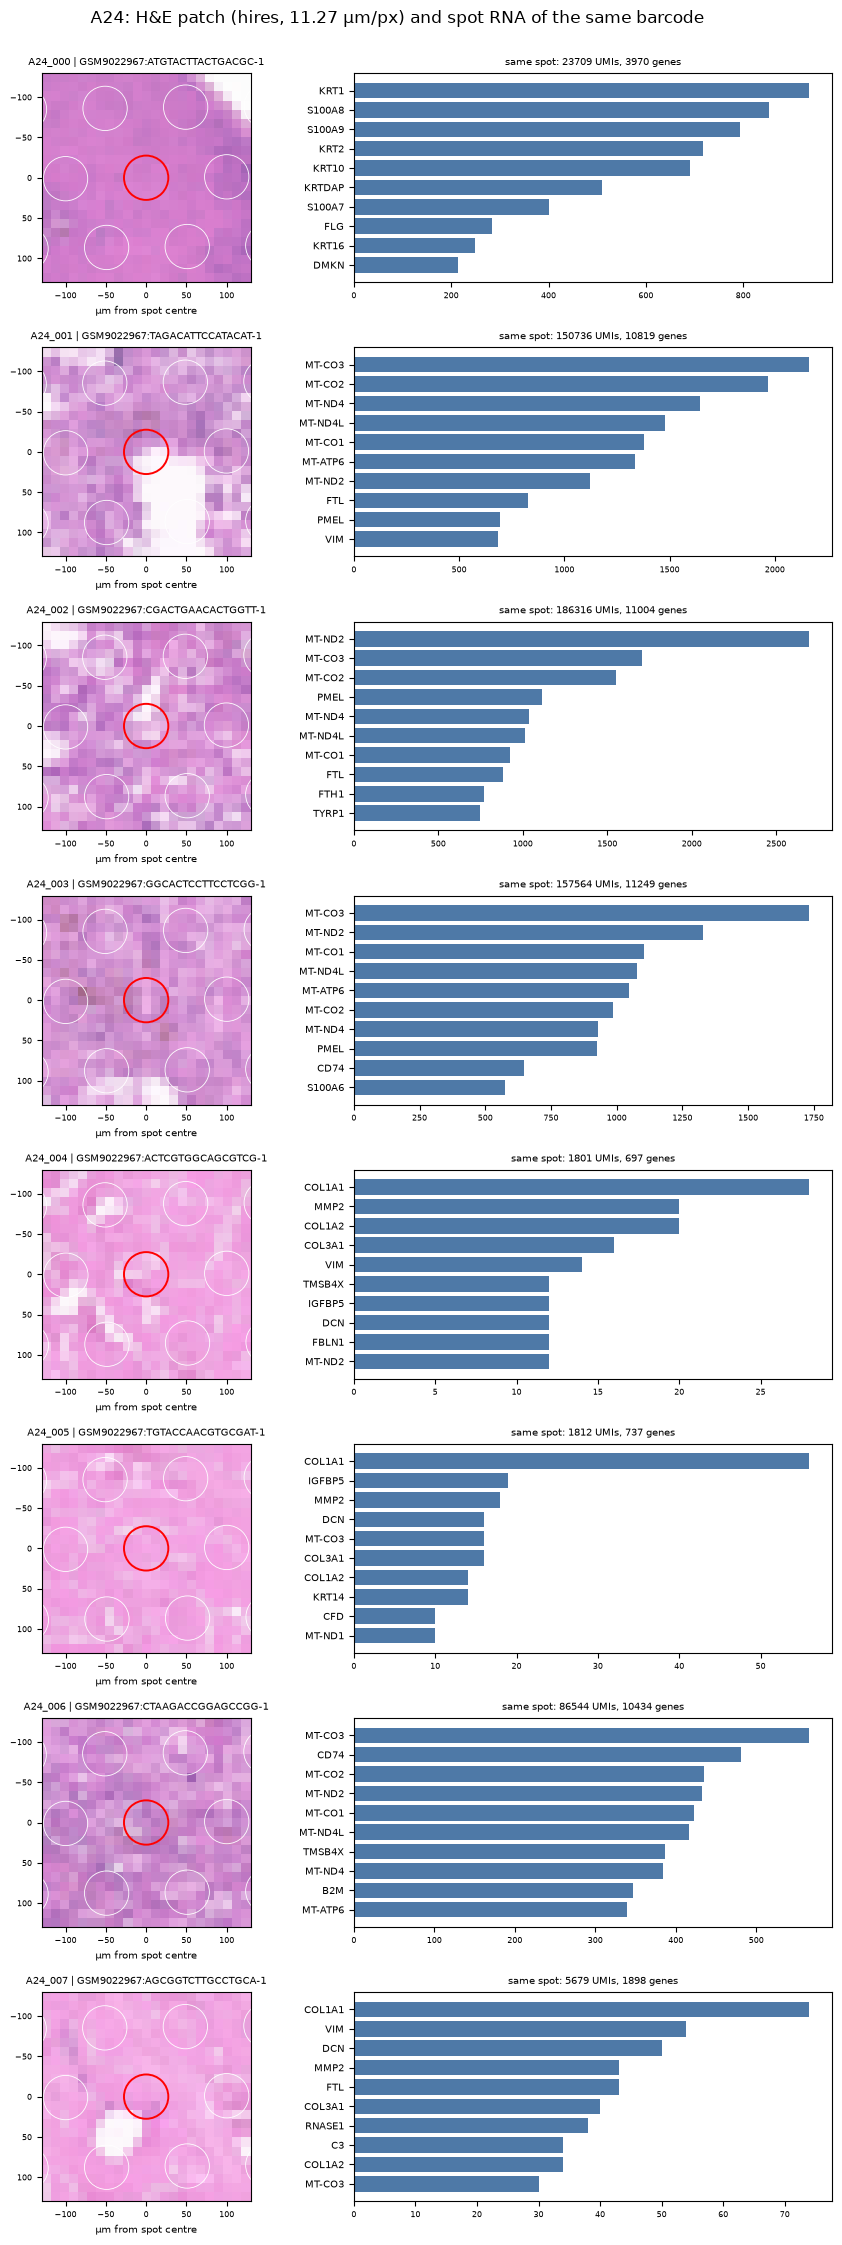

In [12]:
from matplotlib.patches import Circle
for s, r in R.items():
    paired, sel, um_img, ctx_px = r["paired"], r["sel"], r["um_img"], r["ctx_px"]
    pos_all = sio.load_positions(Path(P["raw"]) / r["a_all"].uns["section_meta"]["files"]["positions"])
    um_full = r["a_all"].uns["section_meta"]["um_per_fullres_px"]
    genes = np.asarray(sel.var_names)
    n_show = min(N_MONTAGE, len(paired))
    fig, axes = plt.subplots(n_show, 2, figsize=(9, 2.8 * n_show), gridspec_kw={"width_ratios": [1, 1.3]})
    axes = np.atleast_2d(axes)
    half = ctx_px * um_img / 2
    for k in range(n_show):
        p = paired.iloc[k]
        patch = np.asarray(Image.open(MAN / p.patch_context_file))
        ax = axes[k, 0]
        ax.imshow(patch, extent=[-half, half, half, -half], interpolation="nearest")
        dx = (pos_all.pxl_col_in_fullres - p.pxl_col_in_fullres) * um_full
        dy = (pos_all.pxl_row_in_fullres - p.pxl_row_in_fullres) * um_full
        near = (dx.abs() < half + 30) & (dy.abs() < half + 30)
        for xx, yy in zip(dx[near], dy[near]):
            ax.add_patch(Circle((xx, yy), sio.SPOT_DIAMETER_UM / 2, fill=False, ec="white", lw=0.6))
        ax.add_patch(Circle((0, 0), sio.SPOT_DIAMETER_UM / 2, fill=False, ec="red", lw=1.4))
        ax.set_xlim(-half, half); ax.set_ylim(half, -half)
        ax.set_title(f"{p.pair_id} | {p.spot_uid}", fontsize=7)
        ax.set_xlabel("µm from spot centre", fontsize=7); ax.tick_params(labelsize=6)
        ax = axes[k, 1]
        c = np.asarray(sel.layers["counts"][k].todense()).ravel()
        top = np.argsort(c)[::-1][:10]
        ax.barh(range(10)[::-1], c[top], color="#4e79a7")
        ax.set_yticks(range(10)[::-1]); ax.set_yticklabels(genes[top], fontsize=7)
        ax.set_title(f"same spot: {int(p.total_counts)} UMIs, {int(p.n_genes)} genes", fontsize=7)
        ax.tick_params(axis="x", labelsize=6)
    fig.suptitle(f"{s}: H&E patch ({IMAGE_SOURCE}, {um_img:.2f} µm/px) and spot RNA of the same barcode", y=1.0)
    fig.tight_layout()
    splot.savefig(fig, FIG / f"{r['gsm']}_{s}_pairs_montage.png")
    plt.show()

## 5.11 · Summary across sections

One row per section, collected from the steps above, and saved to `manifests/paired_spots/paired_sections_summary.csv`.
This table only describes the datasets (scale, number of pairs, checks). It does not compare the tissue or the RNA of
the two sections.

In [13]:
summary = pd.DataFrame([{
    "section_id": s, "gsm": r["gsm"], "patient_id": r["paired"].patient_id.iloc[0] if len(r["paired"]) else None,
    "um_per_image_px": round(r["um_img"], 2),
    "patch_context_px": r["ctx_px"], "patch_context_um": round(r["ctx_px"] * r["um_img"], 1),
    "patch_spot_px": r["spot_px"], "patch_spot_um": round(r["spot_px"] * r["um_img"], 1),
    "qc_pass_spots": r["a"].n_obs, "candidates_inside_image": r["n_inside"], "n_pairs": len(r["paired"]),
    "genes_per_profile": r["sel"].n_vars, "min_pair_distance_um": round(r["dmin"], 1),
    "all_checks_passed": all(r["checks"].values()),
    "median_total_counts_selected": float(r["paired"].total_counts.median()),
    "median_n_genes_selected": float(r["paired"].n_genes.median()),
} for s, r in R.items()])
summary.to_csv(MAN / "paired_spots" / "paired_sections_summary.csv", index=False)
summary

,section_id,gsm,patient_id,um_per_image_px,patch_context_px,patch_context_um,patch_spot_px,patch_spot_um,qc_pass_spots,candidates_inside_image,n_pairs,genes_per_profile,min_pair_distance_um,all_checks_passed,median_total_counts_selected,median_n_genes_selected
0,B1,GSM9022969,B1,8.73,29,253.1,7,61.1,3931,3931,40,37082,264.3,True,29004.5,5766.5
1,A24,GSM9022967,A24,11.27,23,259.2,5,56.3,6059,6059,40,37082,264.8,True,18426.0,4700.0


## 5.12 · Visual verification record (from 5.9 and 5.10)

Tissue column: colour and texture only. At 8.7–11.3 µm per pixel a 55 µm spot is 5–6 pixels wide, so tissue types and
cells cannot be named from the patch. The genes in the Notes column are the top genes shown in the montage for that
spot (RNA, not image).

**B1** (8.73 µm/px; context patch 29 px = 253 µm)

| pair_id | Red circle on tissue (yes/no) | Neighbour circles follow the grid (yes/no) | Tissue visible in patch | Notes |
|---|---|---|---|---|
| B1_000 | yes | yes | pale pink, even | 6,702 UMIs; top genes COL1A1, MMP2, COL1A2 |
| B1_001 | yes | yes | darker purple band in the upper half, pink below | 85,021 UMIs; top genes IGKC, IGHM, IGHG1 |
| B1_002 | yes | yes | pale pink with white streaks (unstained gaps) beside the spot | 4,891 UMIs; top genes VIM, COL1A1, DCN |
| B1_003 | yes | yes | pink with purple patches around the spot | 32,238 UMIs; top genes IGHG1, IGKC |
| B1_004 | yes | yes | purple-pink across the whole patch | 81,228 UMIs; top genes FADS2, PM20D1, FASN |
| B1_005 | yes | yes | dense purple, white area at lower right | 75,784 UMIs; top genes CD74, TMSB4X |
| B1_006 | partly: white gap inside the red circle | yes | pale pink with a white diagonal gap through the centre | 2,682 UMIs (lowest of the 8 shown); top genes COL1A1, MMP2, DCN |
| B1_007 | yes | yes | pale pink, small white spots | 7,237 UMIs; top genes VIM, IGKC, MMP2 |

**A24** (11.27 µm/px; context patch 23 px = 259 µm)

| pair_id | Red circle on tissue (yes/no) | Neighbour circles follow the grid (yes/no) | Tissue visible in patch | Notes |
|---|---|---|---|---|
| A24_000 | yes | yes | purple, white in the upper right corner (tissue edge or gap) | 23,709 UMIs; top genes KRT1, S100A8, S100A9, KRT10 |
| A24_001 | partly: white area touches the lower half of the circle | yes | mottled pink-purple with a large white area below the spot | 150,736 UMIs; top genes MT-CO3, MT-CO2, MT-ND4; pct_mt 8.6 % |
| A24_002 | yes | yes | mottled pink-purple, small white patches | 186,316 UMIs; top genes MT-ND2, MT-CO3, PMEL |
| A24_003 | yes | yes | mottled purple, brownish pixels left of the spot | 157,564 UMIs; top genes MT-CO3, MT-ND2; PMEL, CD74 in top 10 |
| A24_004 | yes | yes | pale pink, white patches at upper left | 1,801 UMIs; top genes COL1A1, MMP2, COL1A2 |
| A24_005 | yes | yes | pale pink, even | 1,812 UMIs; top genes COL1A1, IGFBP5, MMP2 |
| A24_006 | yes | yes | purple, even | 86,544 UMIs; top genes MT-CO3, CD74 |
| A24_007 | partly: white area just below the circle | yes | pale pink with a white area at lower left | 5,679 UMIs; top genes COL1A1, VIM, DCN |

## 5.13 · Observations

**B1**
- 3,931 of 3,952 in-tissue spots pass QC; all 3,931 have their whole context patch inside the image (5.3, 5.4).
- 40 pairs selected; minimum distance between selected spots 264.3 µm (≥ 255 µm); all 6 checks True (5.8).
- Context patch 29 px = 253 µm, spot patch 7 px = 61 µm at 8.73 µm/px (5.3).
- Selected spots: median 29,004.5 UMIs and 5,766.5 genes (5.11).
- In the montage, 7 of 8 red circles lie on stained tissue; B1_006 has an unstained gap inside the circle (5.12).

**A24**
- 6,059 of 6,165 in-tissue spots pass QC; all 6,059 have their whole context patch inside the image (5.3, 5.4).
- 40 pairs selected; minimum distance 264.8 µm; all 6 checks True (5.8).
- Context patch 23 px = 259 µm, spot patch 5 px = 56 µm at 11.27 µm/px (5.3).
- Selected spots: median 18,426 UMIs and 4,700 genes (5.11).
- In the location map (5.9), selected spots are spread over both the darker purple region on the right and the paler
  pink region on the left.
- Total UMIs per selected spot in the montage range from 1,801 (A24_004) to 186,316 (A24_002) (5.10).
- In the montage, A24_001 and A24_007 have white (unstained) areas touching or just outside the circle (5.12).

**Both sections (from 5.11 only)**
- Both have 40 pairs, 37,082 genes per profile, and pass all checks.
- A24's image is coarser (11.27 vs 8.73 µm/px), so the same patch size in µm has fewer pixels: 23 vs 29 for the
  context patch and 5 vs 7 for the spot patch.
- Context patch sizes in µm differ slightly because of rounding to whole odd pixel counts (253 vs 259 µm).

Reminder of the limits that apply whatever the outputs show: spot RNA is a mixture of cells; the H&E patch resolution
is set by the distributed image and differs between the two sections; no region labels exist for these spots; no
similarity or retrieval result is claimed.